# Modelo 3 — Bayesian GPLVM: previsão e detecção de anomalias

Usa a tabela `serie` (`02_serie_modelos.ipynb`) e as janelas de `data/exports/<NOME>/modelo3_gplvm/janelas.parquet` (`06_entradas_modelo3_gplvm.ipynb`). **Não baixa dados nem recria a base.**

**Ordem de execução desta versão**

1. **Portão de sanidade do ELBO** (seção 3): treino curto + log-verossimilhança por célula visível. Se estiver fora de faixa, o notebook **para** antes do Optuna.
2. Optuna com semente fixa; os melhores trials são **reavaliados com várias sementes** e a escolha final usa a média.
3. Treino final, com o mesmo diagnóstico de ELBO.
4. Reconstrução (GPLVM × climatologia na mesma interseção de pontos) e conformal aplicado **aos dois**.
5. Detecção com **três escores** (ELBO normalizado por célula visível, LOO diário, climatologia), limiar próprio de cada um vindo da calibração, recall por qualificador e detecção **por janela**.
6. Checagem: o escore da janela não pode estar correlacionado com o número de células visíveis (senão mede missingness).

A janela de 7 dias é contexto local, **não** captura sazonalidade anual. LOO é retrospectivo dentro da janela, não previsão causal.

Use `SMOKE_TEST=True` primeiro (12 estações, poucos trials/épocas, sem LOO).

## 1. Ambiente e imports

In [11]:
import json
from pathlib import Path
import sys

import gpytorch
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
from IPython.display import display

def find_project_root(start=Path.cwd()):
    for folder in (start.resolve(), *start.resolve().parents):
        if (folder / "src" / "main.py").is_file() and (folder / "data" / "exports").is_dir():
            return folder
    raise FileNotFoundError("Abra este notebook dentro do workspace usgs_streamflow.")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import EXPORT_ROOT
from src.evaluation import (
    apply_conformal, conformal_factor, detection_by_group, detection_metrics,
    reconstruction_metrics, threshold_from_calibration, to_cfs,
)
from src.model_exports import gplvm_arrays, load_inputs
from src.model_inputs import select_split
from src.model_data import split_summary
from src.gplvm_anomaly import (
    add_hidden_logp, infer_new_windows, loo_point_scores, predict_windows,
    train_gplvm, training_elbo_diagnostics,
)

print(f"Projeto: {PROJECT_ROOT}")
print(f"PyTorch {torch.__version__} | GPyTorch {gpytorch.__version__} | "
      f"device: {'cuda' if torch.cuda.is_available() else 'cpu'}")

Projeto: C:\Users\kayla\Meu Drive (kaylany.meneses18@gmail.com)\usgs_streamflow
PyTorch 2.15.0+cpu | GPyTorch 1.15.2 | device: cpu


## 2. Carregar a base compartilhada e as janelas exportadas

Mantenha `NOME` igual ao do `02` e do `06`. O smoke test só filtra a entrada em memória.

In [12]:
NOME = "serie_2010_2025_200est"
SMOKE_TEST = False
SMOKE_STATIONS = 12

serie_path = EXPORT_ROOT / f"{NOME}.parquet"
stats_path = EXPORT_ROOT / f"{NOME}_stats.csv"
base_config_path = EXPORT_ROOT / f"{NOME}_config.json"
if not (serie_path.is_file() and stats_path.is_file() and base_config_path.is_file()):
    raise FileNotFoundError(f"Base {NOME!r} incompleta em {EXPORT_ROOT}. Rode o notebook 02 primeiro.")

serie = pd.read_parquet(serie_path)
stats = pd.read_csv(stats_path, index_col="sensor_id")
base_config = json.loads(base_config_path.read_text(encoding="utf-8"))
LOG_TRANSFORM = bool(base_config["splits"]["log_transform"])
serie["sensor_id"] = serie["sensor_id"].astype(str)
stats.index = stats.index.astype(str)

entradas, input_config = load_inputs(NOME, "modelo3_gplvm")
entradas["sensor_id"] = entradas["sensor_id"].astype(str)
if input_config.get("base") != NOME or input_config.get("modelo") != "modelo3_gplvm":
    raise ValueError(f"Configuração de entrada não corresponde à base {NOME!r}: {input_config}")
if set(input_config.get("estacoes", [])) != set(serie["sensor_id"].unique()):
    raise ValueError("A seleção de estações da entrada GPLVM difere da base compartilhada.")
WINDOW = int(input_config["janela"])

if SMOKE_TEST:
    smoke_ids = sorted(serie["sensor_id"].unique())[:SMOKE_STATIONS]
    serie = serie[serie["sensor_id"].isin(smoke_ids)].copy()
    entradas = entradas[entradas["sensor_id"].isin(smoke_ids)].copy()
    stats = stats.loc[stats.index.intersection(smoke_ids)]

gl = gplvm_arrays(entradas)
if gl["Y"].shape[1] != WINDOW:
    raise ValueError(f"Janela da configuração ({WINDOW}) difere da entrada {gl['Y'].shape[1]}.")
if not np.isfinite(gl["Y"]).all() or not np.isfinite(gl["mask"]).all():
    raise ValueError("Y e mask da entrada exportada precisam ser finitos.")
if not set(gl["meta"]["sensor_id"].astype(str)).issubset(set(serie["sensor_id"])):
    raise ValueError("A entrada GPLVM contém estações ausentes na tabela compartilhada.")

SPLITS = ("treino", "validacao", "calibracao", "teste")
blocos = {name: select_split(gl, name) for name in SPLITS}
for name, block in blocos.items():
    if len(block["Y"]) == 0:
        raise ValueError(f"Nenhuma janela exportada para o split {name!r}.")

print(f"Base: {len(serie):,} linhas | {serie['sensor_id'].nunique()} estações")
print(f"Entrada: {len(entradas):,} janelas | janela={WINDOW} dias | smoke test={SMOKE_TEST}")
display(pd.DataFrame({name: {"janelas": len(b["Y"]), "células visíveis": int(b["mask"].sum()),
                             "células escondidas": int(b["hidden"].sum())} for name, b in blocos.items()}).T)
display(split_summary(serie))

KeyboardInterrupt: 

## 3. Configuração, portão de sanidade do ELBO, Optuna e treino final

### 3.1 Configuração e funções auxiliares
Regime de busca mais próximo do final no modo completo (mais janelas e épocas por trial). Semente de treino e semente Monte Carlo de validação **fixas** dentro de cada avaliação.

In [ ]:
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TRAIN_BATCH_SIZE = 128
INFER_BATCH_SIZE = 128
PRED_SAMPLES = 50
RUN_OPTUNA = True
VALIDATION_MC_SEED = SEED + 1000
ELBO_LL_LIMIT = 20.0   # |log-verossimilhança por célula visível| acima disso => erro

if SMOKE_TEST:
    OPTUNA_TRIALS, TOP_K, REPEATS = 3, 2, 2
    TUNE_TRAIN_WINDOWS, TUNE_VALID_WINDOWS = 800, 400
    TUNE_TRAIN_EPOCHS, TUNE_INFER_EPOCHS, TUNE_PRED_SAMPLES = 2, 2, 10
    TRAIN_EPOCHS, INFER_EPOCHS = 3, 5
    RUN_LOO = False
else:
    OPTUNA_TRIALS, TOP_K, REPEATS = 12, 3, 3
    TUNE_TRAIN_WINDOWS, TUNE_VALID_WINDOWS = 30000, 4000
    TUNE_TRAIN_EPOCHS, TUNE_INFER_EPOCHS, TUNE_PRED_SAMPLES = 12, 6, 40
    TRAIN_EPOCHS, INFER_EPOCHS = 30, 15
    RUN_LOO = True

def take_windows(block, indices):
    return {k: (v.iloc[indices].reset_index(drop=True) if k == "meta" else v[indices])
            for k, v in block.items()}

def sample_window_indices(block, limit, seed, require_hidden=False):
    eligible = np.arange(len(block["Y"]))
    if require_hidden:
        eligible = eligible[block["hidden"].sum(axis=1) > 0]
    if not len(eligible):
        raise ValueError("Sem janelas elegíveis.")
    rng = np.random.default_rng(seed)
    return np.sort(rng.choice(eligible, size=min(limit, len(eligible)), replace=False))

train, valid = blocos["treino"], blocos["validacao"]
tune_train = take_windows(train, sample_window_indices(train, TUNE_TRAIN_WINDOWS, SEED))
tune_valid = take_windows(valid, sample_window_indices(valid, TUNE_VALID_WINDOWS, SEED + 1, require_hidden=True))

def check_elbo(diag, history, where):
    ll = diag["log_likelihood_por_celula"]
    if not np.isfinite(ll) or abs(ll) > ELBO_LL_LIMIT:
        raise RuntimeError(
            f"[{where}] log-verossimilhança por célula visível = {ll:.2f} (esperado entre ~-3 e ~1). "
            "Provável bug de máscara, escala N/batch ou KL; não prossiga.")
    if len(history) > 2 and history[-1] < history[0] - 1.0:
        print(f"ATENÇÃO [{where}]: ELBO/célula piorou ao longo do treino "
              f"({history[0]:.3f} -> {history[-1]:.3f}). Reduza a learning rate.")

def elbo_sanity(params, n_windows=2000, epochs=3, seed=SEED):
    torch.manual_seed(seed); np.random.seed(seed)
    sub = take_windows(train, sample_window_indices(train, n_windows, seed))
    m, h = train_gplvm(sub["Y"], sub["mask"], latent_dim=int(params["latent_dim"]),
        n_inducing=int(params["n_inducing"]), nu=float(params["nu"]), epochs=epochs,
        batch_size=TRAIN_BATCH_SIZE, learning_rate=float(params["learning_rate"]), device=DEVICE)
    d = training_elbo_diagnostics(m, sub["Y"], sub["mask"], nu=float(params["nu"]),
        batch_size=INFER_BATCH_SIZE, max_windows=1024, seed=seed)
    return d, h

### 3.2 Portão de sanidade do ELBO (antes do Optuna)
O `train_gplvm` imprime o ELBO por célula visível. A célula abaixo treina rápido com uma configuração conservadora e decompõe o ELBO (log-verossimilhança, KL Student-t, KL latente, KL de indução, todos por célula visível). Se `log_likelihood_por_celula` sair de faixa, levanta erro.

In [ ]:
SANITY_PARAMS = {"latent_dim": 3, "n_inducing": 16, "nu": 4.0, "learning_rate": 0.01}
sanity_diag, sanity_hist = elbo_sanity(SANITY_PARAMS)
display(pd.Series(sanity_diag, name="diagnóstico (sanidade)").to_frame())
print("Histórico ELBO/célula:", [round(x, 3) for x in sanity_hist])
check_elbo(sanity_diag, sanity_hist, "sanidade")
print("OK: ELBO por célula visível dentro da faixa esperada.")

época 01/3 | ELBO estimado/célula visível=-2.5600
época 02/3 | ELBO estimado/célula visível=-2.3295
época 03/3 | ELBO estimado/célula visível=-2.1424


,diagnóstico (sanidade)
janelas_amostradas,1024.000000
celulas_visiveis_amostradas,7168.000000
log_likelihood_por_celula,-1.143339
kl_student_t_por_celula,0.064389
kl_latente_por_celula,0.793076
kl_inducao_por_celula,0.003280
elbo_estimado_por_celula,-2.004083


Histórico ELBO/célula: [-2.56, -2.33, -2.142]
OK: ELBO por célula visível dentro da faixa esperada.


### 3.3 Optuna (semente fixa) + reavaliação dos melhores trials com várias sementes
A escolha final **não** é o melhor trial isolado: os `TOP_K` melhores são reavaliados com `REPEATS` sementes de treino e vence a menor NLPD média. O desvio entre sementes indica se a diferença entre configurações é real. Observação: o plano original previa BoTorch compartilhado; aqui o Optuna (TPE) é usado — declare isso na comparação com os outros modelos ou padronize.

In [ ]:
def score_configuration(params, training_seed):
    torch.manual_seed(training_seed); np.random.seed(training_seed)
    cand, _ = train_gplvm(tune_train["Y"], tune_train["mask"], latent_dim=int(params["latent_dim"]),
        n_inducing=int(params["n_inducing"]), nu=float(params["nu"]), epochs=TUNE_TRAIN_EPOCHS,
        batch_size=TRAIN_BATCH_SIZE, learning_rate=float(params["learning_rate"]), device=DEVICE)
    torch.manual_seed(VALIDATION_MC_SEED); np.random.seed(VALIDATION_MC_SEED)
    q = infer_new_windows(cand, tune_valid["Y"], tune_valid["mask"], nu=float(params["nu"]),
        epochs=TUNE_INFER_EPOCHS, batch_size=INFER_BATCH_SIZE)
    pred = predict_windows(cand, q, tune_valid["Y"], tune_valid["mask"], nu=float(params["nu"]),
        n_samples=TUNE_PRED_SAMPLES, batch_size=INFER_BATCH_SIZE)
    pred = add_hidden_logp(pred, tune_valid, cand, nu=float(params["nu"]))
    score = float(-np.mean(pred["logp_hidden"][tune_valid["hidden"].astype(bool)]))
    del cand, q, pred
    if not np.isfinite(score):
        raise ValueError("NLPD de validação não finito.")
    return score

def objective(trial):
    params = {
        "latent_dim": trial.suggest_int("latent_dim", 2, min(8, WINDOW)),
        "n_inducing": trial.suggest_categorical("n_inducing", [16, 32, 64]),
        "nu": trial.suggest_categorical("nu", [3.0, 4.0, 8.0, 16.0]),
        "learning_rate": trial.suggest_float("learning_rate", 0.003, 0.03, log=True),
    }
    return score_configuration(params, SEED)

if RUN_OPTUNA:
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=OPTUNA_TRIALS)
    display(study.trials_dataframe(attrs=("number", "value", "params", "state")))
    done = sorted([t for t in study.trials if t.value is not None], key=lambda t: t.value)[:TOP_K]
    candidates = [t.params for t in done]
else:
    candidates = [{"latent_dim": 3, "n_inducing": 32, "nu": 4.0, "learning_rate": 0.01}]

rows = []
for i, params in enumerate(candidates):
    scores = [score_configuration(params, SEED + 100 + r) for r in range(REPEATS)]
    rows.append({**params, "nlpd_medio": np.mean(scores),
                 "nlpd_desvio": np.std(scores, ddof=1) if len(scores) > 1 else np.nan})
reeval = pd.DataFrame(rows).sort_values("nlpd_medio").reset_index(drop=True)
display(reeval)
best_params = reeval.iloc[0][["latent_dim", "n_inducing", "nu", "learning_rate"]].to_dict()
print("Hiperparâmetros escolhidos (menor NLPD médio entre sementes):", best_params)

[I 2026-10-28 19:12:58,815] A new study created in memory with name: no-name-a0344fc8-f2f4-4a8c-b298-1311f70751ea


época 01/12 | ELBO estimado/célula visível=-1.9505
época 02/12 | ELBO estimado/célula visível=-1.1895
época 03/12 | ELBO estimado/célula visível=-1.0752
época 04/12 | ELBO estimado/célula visível=-0.9279
época 05/12 | ELBO estimado/célula visível=-0.8196
época 06/12 | ELBO estimado/célula visível=-0.7405
época 07/12 | ELBO estimado/célula visível=-0.6608
época 08/12 | ELBO estimado/célula visível=-0.5952
época 09/12 | ELBO estimado/célula visível=-0.5382
época 10/12 | ELBO estimado/célula visível=-0.4889
época 11/12 | ELBO estimado/célula visível=-0.4490
época 12/12 | ELBO estimado/célula visível=-0.4076


[I 2026-10-28 19:15:10,889] Trial 0 finished with value: -0.1875138282775879 and parameters: {'latent_dim': 4, 'n_inducing': 16, 'nu': 16.0, 'learning_rate': 0.01197391763568503}. Best is trial 0 with value: -0.1875138282775879.


época 01/12 | ELBO estimado/célula visível=-2.6567
época 02/12 | ELBO estimado/célula visível=-1.8098
época 03/12 | ELBO estimado/célula visível=-1.5791
época 04/12 | ELBO estimado/célula visível=-1.4050
época 05/12 | ELBO estimado/célula visível=-1.2386
época 06/12 | ELBO estimado/célula visível=-1.1182
época 07/12 | ELBO estimado/célula visível=-0.9960
época 08/12 | ELBO estimado/célula visível=-0.8938
época 09/12 | ELBO estimado/célula visível=-0.7985
época 10/12 | ELBO estimado/célula visível=-0.7176
época 11/12 | ELBO estimado/célula visível=-0.6473
época 12/12 | ELBO estimado/célula visível=-0.5786


[I 2026-10-28 19:16:45,232] Trial 1 finished with value: -0.18449679017066956 and parameters: {'latent_dim': 6, 'n_inducing': 32, 'nu': 16.0, 'learning_rate': 0.01004332892554779}. Best is trial 0 with value: -0.1875138282775879.


...

[I 2026-10-28 19:35:33,682] Trial 11 finished with value: -0.20708264410495758 and parameters: {'latent_dim': 6, 'n_inducing': 32, 'nu': 8.0, 'learning_rate': 0.004126773735245363}. Best is trial 7 with value: -0.23206202685832977.


,number,value,params_latent_dim,params_learning_rate,params_n_inducing,params_nu,state
0,0,-0.187514,4,0.011974,16,16.0,COMPLETE
1,1,-0.184497,6,0.010043,32,16.0,COMPLETE
2,2,-0.177222,4,0.004751,32,16.0,COMPLETE
3,3,-0.120314,5,0.019298,64,16.0,COMPLETE
4,4,-0.191068,3,0.005444,32,16.0,COMPLETE
5,5,-0.181280,5,0.023548,64,4.0,COMPLETE
6,6,-0.140803,5,0.020224,16,8.0,COMPLETE
7,7,-0.232062,4,0.004741,32,8.0,COMPLETE
8,8,-0.199372,2,0.021889,16,3.0,COMPLETE
9,9,-0.173170,5,0.008899,16,16.0,COMPLETE


época 01/12 | ELBO estimado/célula visível=-2.3311
época 02/12 | ELBO estimado/célula visível=-1.5562
época 03/12 | ELBO estimado/célula visível=-1.1385
época 04/12 | ELBO estimado/célula visível=-0.9684
época 05/12 | ELBO estimado/célula visível=-0.8835
época 06/12 | ELBO estimado/célula visível=-0.8099
época 07/12 | ELBO estimado/célula visível=-0.7380
época 08/12 | ELBO estimado/célula visível=-0.6835
época 09/12 | ELBO estimado/célula visível=-0.6294
época 10/12 | ELBO estimado/célula visível=-0.5861
época 11/12 | ELBO estimado/célula visível=-0.5478
época 12/12 | ELBO estimado/célula visível=-0.5076
época 01/12 | ELBO estimado/célula visível=-2.3141
época 02/12 | ELBO estimado/célula visível=-1.5546
época 03/12 | ELBO estimado/célula visível=-1.1357
época 04/12 | ELBO estimado/célula visível=-0.9683
época 05/12 | ELBO estimado/célula visível=-0.8789
época 06/12 | ELBO estimado/célula visível=-0.8049
época 07/12 | ELBO estimado/célula visível=-0.7412
época 08/12 | ELBO estimado/cél

,latent_dim,n_inducing,nu,learning_rate,nlpd_medio,nlpd_desvio
0,4,32,8.0,0.004741,-0.241065,0.004452
1,6,32,8.0,0.005430,-0.227769,0.007210
2,6,32,8.0,0.004127,-0.208658,0.007795


Hiperparâmetros escolhidos (menor NLPD médio entre sementes): {'latent_dim': 4.0, 'n_inducing': 32.0, 'nu': 8.0, 'learning_rate': 0.004740639559231163}


### 3.4 Treino final e diagnóstico do ELBO

época 01/30 | ELBO estimado/célula visível=-1.6007
época 02/30 | ELBO estimado/célula visível=-0.9244
época 03/30 | ELBO estimado/célula visível=-0.8710
época 04/30 | ELBO estimado/célula visível=-0.7698
época 05/30 | ELBO estimado/célula visível=-0.6951
época 06/30 | ELBO estimado/célula visível=-0.6356
época 07/30 | ELBO estimado/célula visível=-0.5757
época 08/30 | ELBO estimado/célula visível=-0.5238
época 09/30 | ELBO estimado/célula visível=-0.4795
época 10/30 | ELBO estimado/célula visível=-0.4348
época 11/30 | ELBO estimado/célula visível=-0.3957
época 12/30 | ELBO estimado/célula visível=-0.3624
época 13/30 | ELBO estimado/célula visível=-0.3289
época 14/30 | ELBO estimado/célula visível=-0.2995
época 15/30 | ELBO estimado/célula visível=-0.2725
época 16/30 | ELBO estimado/célula visível=-0.2468
época 17/30 | ELBO estimado/célula visível=-0.2235
época 18/30 | ELBO estimado/célula visível=-0.2056
época 19/30 | ELBO estimado/célula visível=-0.1858
época 20/30 | ELBO estimado/cél

,diagnóstico do treino final
janelas_amostradas,2048.000000
celulas_visiveis_amostradas,14328.000000
log_likelihood_por_celula,0.609867
kl_student_t_por_celula,0.114130
kl_latente_por_celula,0.609811
kl_inducao_por_celula,0.004229
elbo_estimado_por_celula,-0.118258


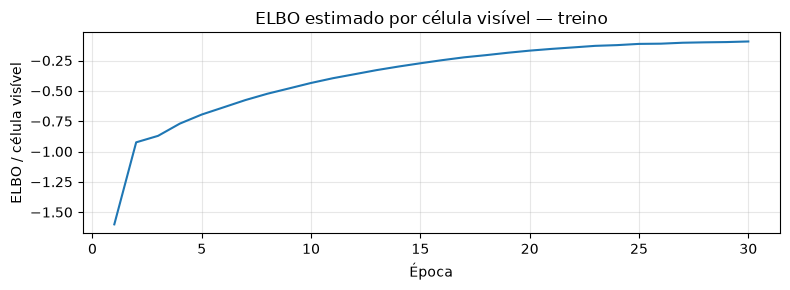

In [ ]:
LATENT_DIM = int(best_params["latent_dim"]); N_INDUCING = int(best_params["n_inducing"])
NU = float(best_params["nu"]); LEARNING_RATE = float(best_params["learning_rate"])

torch.manual_seed(SEED); np.random.seed(SEED)
model, history = train_gplvm(train["Y"], train["mask"], latent_dim=LATENT_DIM, n_inducing=N_INDUCING,
    nu=NU, epochs=TRAIN_EPOCHS, batch_size=TRAIN_BATCH_SIZE, learning_rate=LEARNING_RATE, device=DEVICE)
train_diag = training_elbo_diagnostics(model, train["Y"], train["mask"], nu=NU,
    batch_size=INFER_BATCH_SIZE, max_windows=2048, seed=SEED)
display(pd.Series(train_diag, name="diagnóstico do treino final").to_frame())
check_elbo(train_diag, history, "treino final")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(np.arange(1, len(history) + 1), history)
ax.set(title="ELBO estimado por célula visível — treino", xlabel="Época", ylabel="ELBO / célula visível")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 4. Prever/reconstruir nos blocos posteriores ao treino

`q(X)` de cada janela é inferido só com as células visíveis do bloco; parâmetros globais congelados. O `escore_elbo` vem de `predict_windows` já **dividido pelo número de células visíveis** da janela. A última célula confirma empiricamente que o escore não acompanha o número de visíveis.

In [ ]:
POST = ("validacao", "calibracao", "teste")

def prediction_frame(block, prediction):
    w = block["t_idx"].shape[1]
    return pd.DataFrame({
        "sensor_id": np.repeat(block["meta"]["sensor_id"].astype(str).to_numpy(), w),
        "t": block["t_idx"].ravel(),
        "media": prediction["media"].ravel(), "q025": prediction["q025"].ravel(),
        "q975": prediction["q975"].ravel(), "logp": prediction["logp_hidden"].ravel(),
        "escore_elbo": np.repeat(prediction["escore_elbo"], w),
    })

prediction_frames, window_scores = [], []
for k, name in enumerate(POST):
    block = blocos[name]
    torch.manual_seed(SEED + k + 10)
    latent = infer_new_windows(model, block["Y"], block["mask"], nu=NU,
        epochs=INFER_EPOCHS, batch_size=INFER_BATCH_SIZE)
    pred = predict_windows(model, latent, block["Y"], block["mask"], nu=NU,
        n_samples=PRED_SAMPLES, batch_size=INFER_BATCH_SIZE)
    pred = add_hidden_logp(pred, block, model, nu=NU)
    prediction_frames.append(prediction_frame(block, pred))
    window_scores.append(pd.DataFrame({"split": name, "n_visiveis": block["mask"].sum(axis=1),
                                       "escore_elbo": pred["escore_elbo"]}))
    print(f"{name}: {len(prediction_frames[-1]):,} células previstas")
    del latent, pred

out_base = pd.concat(prediction_frames, ignore_index=True)
if out_base.duplicated(["sensor_id", "t"]).any():
    raise ValueError("Mais de uma previsão para a mesma estação e dia.")
out_base["escore"] = out_base["escore_elbo"]

post_train = serie[serie["split"].isin(POST)]
cov = post_train[["sensor_id", "t"]].merge(out_base[["sensor_id", "t", "media"]],
    on=["sensor_id", "t"], how="left", validate="one_to_one")
print(f"Dias sem previsão (janela descartada/resto incompleto): {cov['media'].isna().sum():,}")
metric_stats = stats if LOG_TRANSFORM else None

# Checagem: o escore da janela mede anomalia ou missingness?
ws = pd.concat(window_scores, ignore_index=True)
corr = ws.groupby("split").apply(lambda g: g["escore_elbo"].rank().corr(g["n_visiveis"].rank()))
display(corr.rename("Spearman(escore, n_visíveis)").to_frame())
if (corr.abs() > 0.3).any():
    print("ATENÇÃO: escore correlacionado com o nº de células visíveis; limiar global pode medir missingness.")

validacao: 170,863 células previstas
calibracao: 113,750 células previstas
teste: 164,094 células previstas
Dias sem previsão (janela descartada/resto incompleto): 18,893


,"Spearman(escore, n_visíveis)"
split,
calibracao,-0.074315
teste,-0.061022
validacao,-0.064899


## 5. Baseline climatológico e comparação na mesma interseção

Média por estação e dia do ano (só treino visível). GPLVM e baseline são avaliados **nos mesmos pontos**; a tabela de cobertura mostra a fração dos escondidos com previsão do GPLVM.

In [ ]:
def climatology_predictions(table):
    rows = []
    fit_all = table[(table["split"] == "treino") & (table["visivel"] == 1)].copy()
    fit_all["doy"] = pd.to_datetime(fit_all["data"]).dt.dayofyear.clip(upper=365)
    for sid, group in table[table["split"].isin(POST)].groupby("sensor_id"):
        fit = fit_all[fit_all["sensor_id"] == sid]
        if fit.empty:
            continue
        by_doy = fit.groupby("doy")["y"].mean(); fallback = float(fit["y"].mean())
        resid = (fit["y"] - fit["doy"].map(by_doy).fillna(fallback)).dropna()
        if len(resid) < 2:
            raise ValueError(f"Resíduos insuficientes na estação {sid}.")
        pred = group.copy()
        doy = pd.to_datetime(pred["data"]).dt.dayofyear.clip(upper=365)
        mu = doy.map(by_doy).fillna(fallback).to_numpy(float)
        scale = max(float(resid.std(ddof=1)), 1e-3)
        z = (pred["y"].to_numpy(float) - mu) / scale
        pred["media"] = mu
        pred["q025"] = mu + float(resid.quantile(0.025)); pred["q975"] = mu + float(resid.quantile(0.975))
        pred["escore"] = np.abs(z)
        pred["logp"] = -0.5 * np.log(2 * np.pi) - np.log(scale) - 0.5 * z ** 2
        rows.append(pred[["sensor_id", "t", "media", "q025", "q975", "escore", "logp"]])
    if not rows:
        raise ValueError("Sem previsões de climatologia.")
    return pd.concat(rows, ignore_index=True)

out_clim = climatology_predictions(serie)
hidden_keys = serie.loc[serie["escondido_aval"] == 1, ["sensor_id", "t", "split"]]
pred_hidden = hidden_keys.merge(out_base[["sensor_id", "t"]], on=["sensor_id", "t"], how="inner", validate="one_to_one")
display(pd.DataFrame([{"split": s, "pontos_escondidos": len(g),
    "com_previsao": int((pred_hidden["split"] == s).sum()),
    "cobertura": (pred_hidden["split"] == s).sum() / len(g)} for s, g in hidden_keys.groupby("split")]).set_index("split"))

common_keys = out_base[["sensor_id", "t"]].merge(out_clim[["sensor_id", "t"]], on=["sensor_id", "t"],
    how="inner", validate="one_to_one").drop_duplicates()
common_serie = serie.merge(common_keys, on=["sensor_id", "t"], how="inner", validate="one_to_one")
display(pd.concat({s: pd.DataFrame({
    "GPLVM": reconstruction_metrics(common_serie, out_base, split=s, stats=metric_stats),
    "climatologia": reconstruction_metrics(common_serie, out_clim, split=s, stats=metric_stats)}).T
    for s in POST}, names=["split", "modelo"]))

C:\Users\kayla\AppData\Local\Temp\ipykernel_12052\234362507.py:4: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  fit_all["doy"] = pd.to_datetime(fit_all["data"]).dt.dayofyear.clip(upper=365)
C:\Users\kayla\AppData\Local\Temp\ipykernel_12052\234362507.py:14: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  doy = pd.to_datetime(pred["data"]).dt.dayofyear.clip(upper=365)
C:\Users\kayla\AppData\Local\Temp\ipykernel_12052\234362507.py:14: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  doy = pd.to_datetime(pred["data"]).dt.dayofyear.clip(upper=365)
C:\Users\kayla\AppData\Local\Temp\ipykernel_12052\234362507.py:14: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  doy = pd.to_dat

,pontos_escondidos,com_previsao,cobertura
split,,,
calibracao,11342,11129,0.981220
teste,16305,16052,0.984483
validacao,16993,16691,0.982228


n         rmse         mae  cobertura_95  \
split      modelo                                                         
validacao  GPLVM         16691.0  1278.584582  246.773967      0.729914   
           climatologia  16691.0  2681.407499  523.344431      0.935894   
calibracao GPLVM         11129.0  1175.891710  261.437306      0.786054   
           climatologia  11129.0  3370.259267  721.393322      0.898643   
teste      GPLVM         16052.0  1176.122426  264.334623      0.737291   
           climatologia  16052.0  2426.222721  546.174572      0.932407   

                         largura_media  interval_score      nlpd  
split      modelo                                                 
validacao  GPLVM            730.769111     2563.911913  0.643997  
           climatologia    3470.078956     4520.550953  1.157305  
calibracao GPLVM            883.272938     2616.743427  0.487763  
           climatologia    4019.409447     6298.293808  1.723526  
teste      GPLVM            851.261548     2686.836286  0.692007  
           climatologia    3564.241422     4868.879783  1.427315

## 6. Calibração conformal (GPLVM **e** baseline) e margem dos intervalos
Fator global ajustado nos escondidos da calibração, aplicado ao GPLVM e à climatologia para que cobertura e largura sejam comparáveis. A cobertura é aproximada (heterogeneidade entre estações e dependência temporal).

In [ ]:
ALPHA = 0.05
cal_hidden = serie[(serie["split"] == "calibracao") & (serie["escondido_aval"] == 1)].merge(
    out_base[["sensor_id", "t", "media"]], on=["sensor_id", "t"], how="left",
    validate="one_to_one").dropna(subset=["media"])
if len(cal_hidden) == 0:
    raise ValueError("A calibração não tem pontos escondidos para o fator conformal.")

factor = conformal_factor(serie, out_base, alpha=ALPHA)
clim_factor = conformal_factor(serie, out_clim, alpha=ALPHA)
out_conf = apply_conformal(out_base, factor)
out_clim_conf = apply_conformal(out_clim, clim_factor)
print(f"Fator conformal {1-ALPHA:.0%}: GPLVM={factor:.4f} | climatologia={clim_factor:.4f} | "
      f"pontos de calibração GPLVM={len(cal_hidden):,}")

display(pd.concat({s: pd.DataFrame({
    "GPLVM — inicial": reconstruction_metrics(common_serie, out_base, split=s, stats=metric_stats),
    "GPLVM — conformal": reconstruction_metrics(common_serie, out_conf, split=s, stats=metric_stats),
    "climatologia — inicial": reconstruction_metrics(common_serie, out_clim, split=s, stats=metric_stats),
    "climatologia — conformal": reconstruction_metrics(common_serie, out_clim_conf, split=s, stats=metric_stats)}).T
    for s in POST}, names=["split", "intervalo"]))

margin = serie[["sensor_id", "t", "split", "escondido_aval"]].merge(
    out_base[["sensor_id", "t", "q025", "q975"]].rename(columns={"q025": "lo_base", "q975": "hi_base"}),
    on=["sensor_id", "t"], how="left", validate="one_to_one").merge(
    out_conf[["sensor_id", "t", "q025", "q975"]].rename(columns={"q025": "lo_conf", "q975": "hi_conf"}),
    on=["sensor_id", "t"], how="left", validate="one_to_one")
margin = margin[margin["split"].isin(["calibracao", "teste"]) & (margin["escondido_aval"] == 1)
                & margin["lo_conf"].notna()].copy()
cf = lambda s: to_cfs(s, margin["sensor_id"], stats, log_transform=LOG_TRANSFORM)
margin["margem_inferior_y"] = margin["lo_base"] - margin["lo_conf"]
margin["margem_superior_y"] = margin["hi_conf"] - margin["hi_base"]
margin["margem_inferior_cfs"] = cf(margin["lo_base"]) - cf(margin["lo_conf"])
margin["margem_superior_cfs"] = cf(margin["hi_conf"]) - cf(margin["hi_base"])
display(pd.DataFrame([{"split": s, "margem": c, "mediana": g[c].median(), "p90": g[c].quantile(0.9)}
    for s, g in margin.groupby("split")
    for c in ("margem_inferior_y", "margem_superior_y", "margem_inferior_cfs", "margem_superior_cfs")]))

Fator conformal 95%: GPLVM=1.7925 | climatologia=1.2421 | pontos de calibração GPLVM=11,129


n         rmse         mae  \
split      intervalo                                                    
validacao  GPLVM — inicial           16691.0  1278.584582  246.773967   
           GPLVM — conformal         16691.0  1278.584582  246.773967   
           climatologia — inicial    16691.0  2681.407499  523.344431   
           climatologia — conformal  16691.0  2681.407499  523.344431   
calibracao GPLVM — inicial           11129.0  1175.891710  261.437306   
           GPLVM — conformal         11129.0  1175.891710  261.437306   
           climatologia — inicial    11129.0  3370.259267  721.393322   
           climatologia — conformal  11129.0  3370.259267  721.393322   
teste      GPLVM — inicial           16052.0  1176.122426  264.334623   
           GPLVM — conformal         16052.0  1176.122426  264.334623   
           climatologia — inicial    16052.0  2426.222721  546.174572   
           climatologia — conformal  16052.0  2426.222721  546.174572   

                                     cobertura_95  largura_media  \
split      intervalo                                               
validacao  GPLVM — inicial               0.729914     730.769111   
           GPLVM — conformal             0.942484    2541.994306   
           climatologia — inicial        0.935894    3470.078956   
           climatologia — conformal      0.972560    5197.387331   
calibracao GPLVM — inicial               0.786054     883.272938   
           GPLVM — conformal             0.950130    1765.530779   
           climatologia — inicial        0.898643    4019.409447   
           climatologia — conformal      0.950220    6062.788709   
teste      GPLVM — inicial               0.737291     851.261548   
           GPLVM — conformal             0.941440    1873.386009   
           climatologia — inicial        0.932407    3564.241422   
           climatologia — conformal      0.966172    5328.276360   

                                     interval_score      nlpd  
split      intervalo                                           
validacao  GPLVM — inicial              2563.911913  0.643997  
           GPLVM — conformal            2968.900222  0.643997  
           climatologia — inicial       4520.550953  1.157305  
           climatologia — conformal     5528.065863  1.157305  
calibracao GPLVM — inicial              2616.743427  0.487763  
           GPLVM — conformal            2261.997711  0.487763  
           climatologia — inicial       6298.293808  1.723526  
           climatologia — conformal     6916.006542  1.723526  
teste      GPLVM — inicial              2686.836286  0.692007  
           GPLVM — conformal            2344.024596  0.692007  
           climatologia — inicial       4868.879783  1.427315  
           climatologia — conformal     6042.183288  1.427315

,split,margem,mediana,p90
0,calibracao,margem_inferior_y,0.258001,0.385209
1,calibracao,margem_superior_y,0.262397,0.401055
2,calibracao,margem_inferior_cfs,16.685544,409.058130
3,calibracao,margem_superior_cfs,48.883517,1219.271694
4,teste,margem_inferior_y,0.263793,0.415312
5,teste,margem_superior_y,0.268702,0.444107
6,teste,margem_inferior_cfs,14.687797,372.704581
7,teste,margem_superior_cfs,46.315374,1174.435878


## 7. Detecção de anomalias

Três escores comparados **na mesma interseção de dias**, cada um com limiar p99 da própria calibração (rótulos só entram nas métricas):

- **ELBO por célula visível/janela** (convenção comum, repetido nos dias da janela);
- **LOO diário** (só no modo completo);
- **Climatologia** (baseline; sem ele, um AUC próximo de 0,5 não é interpretável).

Reportamos (a) detecção **por dia**, (b) recall por qualificador (atenção a `Fld`, onde se espera o sinal; `ESTIMATED;ICE`/`EQUIP` são valores suaves e o LOO tende a achá-los normais, AUC ≤ 0,5 é plausível) e (c) detecção **por janela** (a janela contém alguma anomalia?), pois o rótulo é diário e o escore é por janela.

In [ ]:
LOO_CHUNK_WINDOWS, LOO_INFER_EPOCHS, LOO_SAMPLES, ALERT_QUANTILE = 128, 8, 30, 0.99

out_window_score = out_base.copy()
out_window_score["escore"] = out_window_score["escore_elbo"]

loo_out = pd.DataFrame({"sensor_id": pd.Series(dtype=str), "t": pd.Series(dtype="int64"),
                        "escore_loo": pd.Series(dtype="float32")})
if RUN_LOO:
    frames = []
    for k, name in enumerate(POST):
        print(f"\nLOO: {name}")
        block = blocos[name]
        torch.manual_seed(SEED + k + 20)
        scores = loo_point_scores(model, block, nu=NU, chunk_windows=LOO_CHUNK_WINDOWS,
            infer_epochs=LOO_INFER_EPOCHS, n_samples=LOO_SAMPLES, infer_batch_size=INFER_BATCH_SIZE)
        w = block["t_idx"].shape[1]
        frames.append(pd.DataFrame({
            "sensor_id": np.repeat(block["meta"]["sensor_id"].astype(str).to_numpy(), w),
            "t": block["t_idx"].ravel().astype("int64"), "escore_loo": scores.ravel()}))
    loo_out = pd.concat(frames, ignore_index=True)

out_eval = out_base.merge(loo_out, on=["sensor_id", "t"], how="left", validate="one_to_one")
out_loo_score = out_eval.copy(); out_loo_score["escore"] = out_loo_score["escore_loo"]

keys = out_window_score[["sensor_id", "t"]].merge(out_clim[["sensor_id", "t"]],
    on=["sensor_id", "t"], how="inner", validate="one_to_one")
if RUN_LOO:
    keys = keys.merge(out_loo_score[["sensor_id", "t"]].loc[out_loo_score["escore"].notna()],
        on=["sensor_id", "t"], how="inner", validate="one_to_one")
detection_serie = serie.merge(keys, on=["sensor_id", "t"], how="inner", validate="one_to_one")

detection_models = {
    "ELBO por célula visível/janela": out_window_score.merge(keys, on=["sensor_id", "t"], validate="one_to_one"),
    "Climatologia": out_clim.merge(keys, on=["sensor_id", "t"], validate="one_to_one"),
}
if RUN_LOO:
    detection_models["LOO diário"] = out_loo_score.merge(keys, on=["sensor_id", "t"], validate="one_to_one")

thresholds, metric_rows, group_tables = {}, [], []
for name, sc in detection_models.items():
    thr = threshold_from_calibration(detection_serie, sc, quantile=ALERT_QUANTILE)
    if not np.isfinite(thr):
        raise ValueError(f"Sem escores de calibração para {name}.")
    thresholds[name] = thr
    print(f"Limiar {name} p{ALERT_QUANTILE:.0%}: {thr:.4f}")
    for s in ("validacao", "teste"):
        r = detection_metrics(detection_serie, sc, thr, split=s); r["escore"] = name; r["split"] = s
        metric_rows.append(r)
    g = detection_by_group(detection_serie, sc, thr, split="teste")
    if not g.empty:
        g.insert(0, "escore", name); group_tables.append(g)
print("\nDetecção por dia:")
display(pd.DataFrame(metric_rows).set_index(["escore", "split"]))
if group_tables:
    print("Recall por qualificador / AUC por aprovação (teste):")
    display(pd.concat(group_tables, ignore_index=True))

def window_detection_inputs(score_out):
    parts = []
    for s in POST:
        b = blocos[s]; w = b["t_idx"].shape[1]
        dm = pd.DataFrame({"sensor_id": np.repeat(b["meta"]["sensor_id"].astype(str).to_numpy(), w),
                           "t": b["t_idx"].ravel(), "window_t": np.repeat(b["t_idx"][:, 0], w)})
        dm = dm.merge(score_out[["sensor_id", "t", "escore"]], on=["sensor_id", "t"], how="inner", validate="one_to_one")
        dm = dm.merge(serie[["sensor_id", "t", "split", "visivel", "anomalia"]], on=["sensor_id", "t"],
                      how="inner", validate="one_to_one")
        dm = dm[(dm["split"] == s) & (dm["visivel"] == 1) & dm["escore"].notna()]
        agg = dm.groupby(["sensor_id", "split", "window_t"], as_index=False).agg(
            anomalia=("anomalia", "max"), escore=("escore", "max"))
        agg["visivel"] = 1; agg["t"] = agg["window_t"]
        parts.append(agg[["sensor_id", "t", "split", "visivel", "anomalia", "escore"]])
    ws_all = pd.concat(parts, ignore_index=True)
    wo = ws_all[["sensor_id", "t", "escore"]].copy()
    # `serie` não pode ter coluna `escore`: evaluation._join faz merge com `out` e duplicaria o nome (escore_x/escore_y).
    ws_ = ws_all.drop(columns=["escore"])
    wo["media"], wo["q025"], wo["q975"] = 0.0, -1.0, 1.0
    return ws_, wo[["sensor_id", "t", "media", "q025", "q975", "escore"]]

wrows = []
for name, sc in detection_models.items():
    w_serie, w_out = window_detection_inputs(sc)
    thr = threshold_from_calibration(w_serie, w_out, quantile=ALERT_QUANTILE)
    for s in ("validacao", "teste"):
        r = detection_metrics(w_serie, w_out, thr, split=s); r["escore"] = name; r["split"] = s
        wrows.append(r)
print("\nDetecção por janela (a janela contém alguma anomalia?):")
display(pd.DataFrame(wrows).set_index(["escore", "split"]))

test_labels = serie[(serie["split"] == "teste") & (serie["anomalia"] == 1)]
test_scored = test_labels.merge(out_eval[["sensor_id", "t", "escore_loo"]], on=["sensor_id", "t"],
                                how="left", validate="one_to_one")
display(pd.Series({
    "anomalias rotuladas no teste": len(test_labels),
    "com valor observado": int(test_labels["observado"].eq(1).sum()),
    "visíveis para detecção": int(test_labels["visivel"].eq(1).sum()),
    "com escore LOO": int(test_scored["escore_loo"].notna().sum()),
}, name="reconciliação de anomalias").to_frame())


LOO: validacao
dia 1/7: lote 25/173
dia 1/7: lote 50/173
dia 1/7: lote 75/173
dia 1/7: lote 100/173
dia 1/7: lote 125/173
dia 1/7: lote 150/173
dia 1/7: lote 173/173
dia 2/7: lote 25/173
dia 2/7: lote 50/173
dia 2/7: lote 75/173
dia 2/7: lote 100/173
dia 2/7: lote 125/173
dia 2/7: lote 150/173
dia 2/7: lote 173/173
dia 3/7: lote 25/172
dia 3/7: lote 50/172
dia 3/7: lote 75/172
dia 3/7: lote 100/172
dia 3/7: lote 125/172
dia 3/7: lote 150/172
dia 3/7: lote 172/172
dia 4/7: lote 25/173
dia 4/7: lote 50/173
dia 4/7: lote 75/173
dia 4/7: lote 100/173
dia 4/7: lote 125/173
dia 4/7: lote 150/173
dia 4/7: lote 173/173
dia 5/7: lote 25/173
dia 5/7: lote 50/173
dia 5/7: lote 75/173
dia 5/7: lote 100/173
dia 5/7: lote 125/173
dia 5/7: lote 150/173
dia 5/7: lote 173/173
dia 6/7: lote 25/173
dia 6/7: lote 50/173
dia 6/7: lote 75/173
dia 6/7: lote 100/173
dia 6/7: lote 125/173
dia 6/7: lote 150/173
dia 6/7: lote 173/173
dia 7/7: lote 25/172
dia 7/7: lote 50/172
dia 7/7: lote 75/172
dia 7/7: lote 1

KeyboardInterrupt: 

## 8. Inspecionar escores, espaço latente e previsão

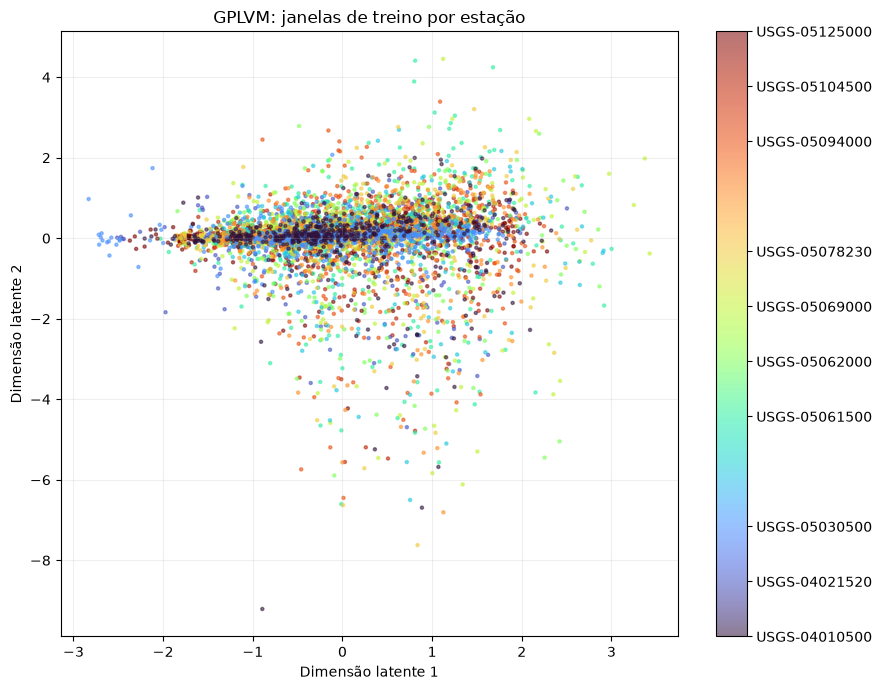

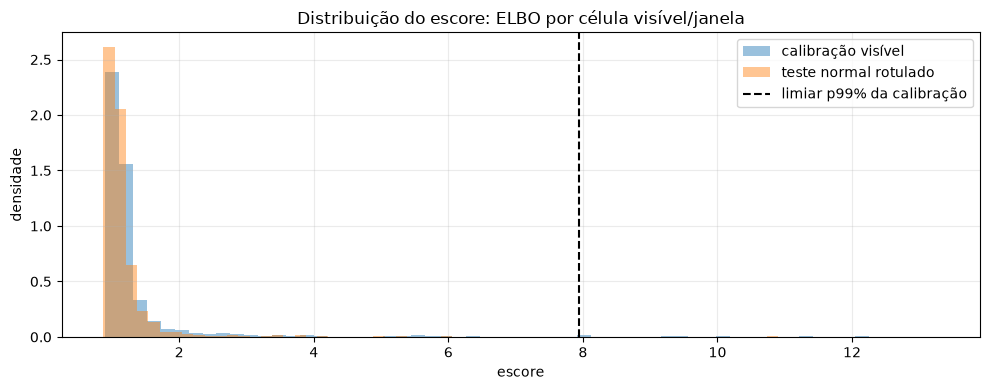

Estação exibida: USGS-05104500 (apenas inspeção visual).


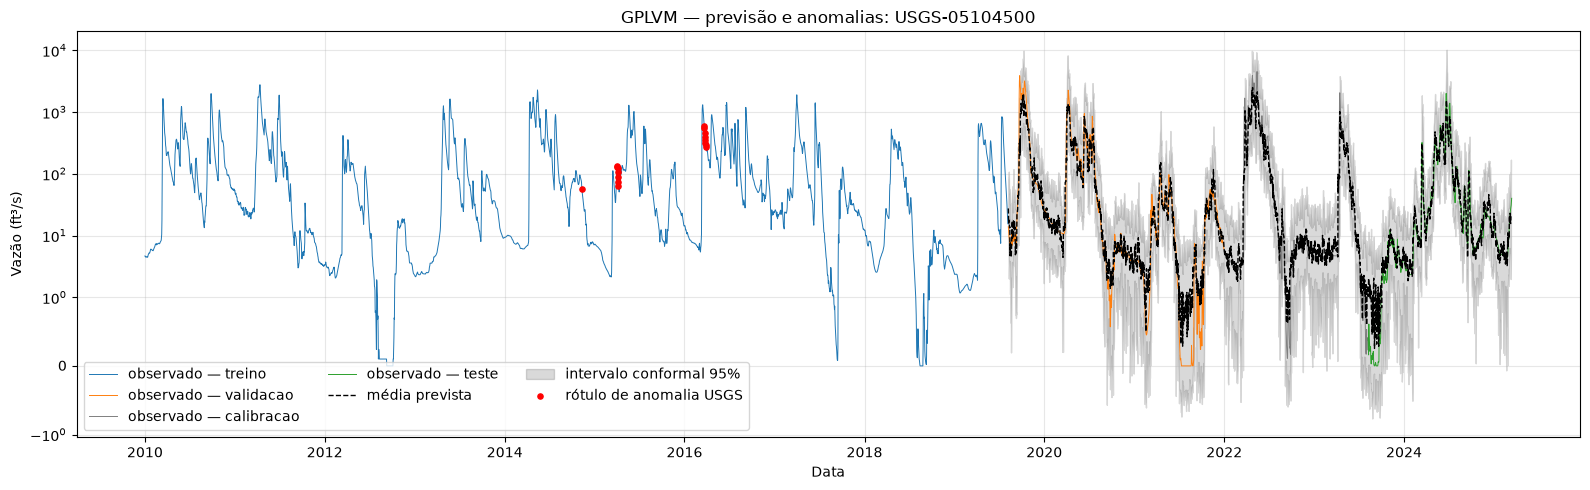

In [ ]:
joined = serie.merge(out_conf, on=["sensor_id", "t"], how="left", validate="one_to_one")

# espaço latente (treino)
latent_xy = model.X.q_mu.detach().cpu().numpy()
if latent_xy.ndim == 3:
    latent_xy = latent_xy.mean(axis=1)
if latent_xy.shape[1] < 2 or len(latent_xy) != len(train["meta"]):
    raise ValueError("Formato inesperado do espaço latente ou metadados de treino.")
lp = train["meta"][["sensor_id"]].reset_index(drop=True).copy()
lp["z1"], lp["z2"] = latent_xy[:, 0], latent_xy[:, 1]
if len(lp) > 25000:
    lp = lp.sample(25000, random_state=SEED)
codes = pd.Categorical(lp["sensor_id"])
fig, ax = plt.subplots(figsize=(9, 7))
pts = ax.scatter(lp["z1"], lp["z2"], c=codes.codes, cmap="turbo", s=5, alpha=0.55, rasterized=True)
cb = fig.colorbar(pts, ax=ax)
tick = np.unique(np.linspace(0, len(codes.categories) - 1, min(10, len(codes.categories))).round().astype(int))
cb.set_ticks(tick); cb.set_ticklabels([codes.categories[i] for i in tick])
ax.set(title="GPLVM: janelas de treino por estação", xlabel="Dimensão latente 1", ylabel="Dimensão latente 2")
ax.grid(alpha=0.2); plt.tight_layout(); plt.show()

# distribuição do escore principal (LOO se existir, senão ELBO/janela)
key = "LOO diário" if "LOO diário" in detection_models else "ELBO por célula visível/janela"
sc = detection_models[key].merge(serie[["sensor_id", "t", "split", "visivel", "anomalia"]],
                                 on=["sensor_id", "t"], validate="one_to_one")
cal = sc.loc[(sc["split"] == "calibracao") & (sc["visivel"] == 1), "escore"]
tn = sc.loc[(sc["split"] == "teste") & (sc["visivel"] == 1) & (sc["anomalia"] == 0), "escore"]
ta = sc.loc[(sc["split"] == "teste") & (sc["visivel"] == 1) & (sc["anomalia"] == 1), "escore"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(cal, bins=60, density=True, alpha=0.45, label="calibração visível")
ax.hist(tn, bins=60, density=True, alpha=0.45, label="teste normal rotulado")
if len(ta):
    ax.hist(ta, bins=30, density=True, alpha=0.6, label="anomalia rotulada no teste")
ax.axvline(thresholds[key], color="black", ls="--", label=f"limiar p{ALERT_QUANTILE:.0%} da calibração")
ax.set(title=f"Distribuição do escore: {key}", xlabel="escore", ylabel="densidade")
ax.legend(); ax.grid(alpha=0.25); plt.tight_layout(); plt.show()

# série de uma estação (escolha só para inspeção visual)
PLOT_STATION = "USGS-11224000"
by_st = joined[(joined["split"] == "teste") & (joined["anomalia"] == 1)].groupby("sensor_id").size()
if PLOT_STATION not in set(joined["sensor_id"]) or by_st.get(PLOT_STATION, 0) == 0:
    PLOT_STATION = str(by_st.idxmax()) if not by_st.empty else sorted(joined["sensor_id"].unique())[0]
print(f"Estação exibida: {PLOT_STATION} (apenas inspeção visual).")
s = joined[joined["sensor_id"] == PLOT_STATION].sort_values("data").copy()
p = s[s["split"].isin(POST) & s["media"].notna()].copy()
for col, new in (("media", "media_cfs"), ("q025", "lo_cfs"), ("q975", "hi_cfs")):
    p[new] = to_cfs(p[col], p["sensor_id"], stats, log_transform=LOG_TRANSFORM)
colors = {"treino": "tab:blue", "validacao": "tab:orange", "calibracao": "tab:gray", "teste": "tab:green"}
fig, ax = plt.subplots(figsize=(16, 5))
for n, c in colors.items():
    g = s[(s["split"] == n) & (s["observado"] == 1)]
    ax.plot(g["data"], g["y_bruto"], color=c, lw=0.7, label=f"observado — {n}")
ax.plot(p["data"], p["media_cfs"], "k--", lw=1.0, label="média prevista")
ax.fill_between(p["data"], p["lo_cfs"], p["hi_cfs"], color="black", alpha=0.15, label="intervalo conformal 95%")
an = s[(s["anomalia"] == 1) & (s["observado"] == 1)]
ax.scatter(an["data"], an["y_bruto"], color="red", s=14, zorder=4, label="rótulo de anomalia USGS")
ax.set_yscale("symlog", linthresh=1)
ax.set(title=f"GPLVM — previsão e anomalias: {PLOT_STATION}", xlabel="Data", ylabel="Vazão (ft³/s)")
ax.grid(alpha=0.3); ax.legend(ncol=3); plt.tight_layout(); plt.show()

## 9. Exportar resultados (opcional)
Por padrão não grava. Mude `EXPORT_RESULTS` para `True`; recusa sobrescrever. Colunas: `sensor_id`, `t`, `media`, `q025`, `q975`, `escore` (ELBO normalizado por célula visível) e `escore_loo` (análise adicional).

In [15]:
EXPORT_RESULTS = True
if EXPORT_RESULTS:
    destination = EXPORT_ROOT / f"{NOME}_modelo3_gplvm_resultados.parquet"
    if destination.exists():
        raise FileExistsError(f"Não vou sobrescrever {destination}")
    out_model = out_conf.merge(loo_out, on=["sensor_id", "t"], how="left", validate="one_to_one")
    out_model["escore"] = out_model["escore_elbo"]
    out_model[["sensor_id", "t", "media", "q025", "q975", "escore", "escore_loo"]].to_parquet(destination, index=False)
    print(f"Resultados salvos em {destination}")

Resultados salvos em C:\Users\kayla\Meu Drive (kaylany.meneses18@gmail.com)\usgs_streamflow\data\exports\serie_2010_2025_200est_modelo3_gplvm_resultados.parquet
